In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy as sp
from matplotlib.colors import LogNorm
from matplotlib import colors
from scipy.stats import norm
from scipy.stats import spearmanr

In [ ]:
file_path_P = "/obs/kkesri/code/python/datasets/df_final_results_P.csv" 
file_path_B = "/obs/kkesri/code/python/datasets/df_final_results_B.csv" 
file_path_N = "/obs/kkesri/code/python/datasets/df_final_results_N.csv" 

df_final_P = pd.read_csv(file_path_P, index_col=0, parse_dates=True)
df_final_B = pd.read_csv(file_path_B, index_col=0, parse_dates=True)
df_final_N = pd.read_csv(file_path_N, index_col=0, parse_dates=True)

print(df_final_P.shape)

(132, 40)


In [6]:
def spearman_test(df, xcol, ycol, mask=None, label=""):
    
    data = df[[xcol, ycol]].dropna()

    if mask is not None:
        data = data.loc[mask(data)]

    rho, p = spearmanr(data[xcol], data[ycol])

    print(label)
    print(f"N = {len(data)}")
    print(f"Spearman rho = {rho:.3f}")
    print(f"p-value = {p:.4g}")
    print()

    return rho, p

In [11]:
rho_peak, p_peak = spearman_test(
    df_final_P,
    "forcing_peak_value",
    "peak_log",
    label="P_dyn peak vs bKOM peak"
)

rho_duration, p_duration = spearman_test(
    df_final_P,
    "forcing_duration_hr",
    "active_duration_hr",
    mask=lambda d: d["active_duration_hr"] > 20,
    label="Forcing duration vs bKOM active duration"
)

P_dyn peak vs bKOM peak
N = 132
Spearman rho = 0.044
p-value = 0.6163

Forcing duration vs bKOM active duration
N = 75
Spearman rho = 0.005
p-value = 0.9673



In [12]:
data_duration = df_final_P[
    ["forcing_duration_hr", "active_duration_hr"]
].dropna()

data_duration = data_duration[
    data_duration["active_duration_hr"] > 10
]

rho_duration, p_duration = spearmanr(
    data_duration["forcing_duration_hr"],
    data_duration["active_duration_hr"]
)

print("Forcing duration vs bKOM active duration")
print(f"N = {len(data_duration)}")
print(f"Spearman rho = {rho_duration:.3f}")
print(f"p-value = {p_duration:.4g}")

Forcing duration vs bKOM active duration
N = 77
Spearman rho = -0.004
p-value = 0.9738


In [4]:
i=0
for item in df_final_P["n_peaks"]:
    if item != 0:
        i+=1

print(i, df_final_P["n_peaks"].shape)

84 (132,)


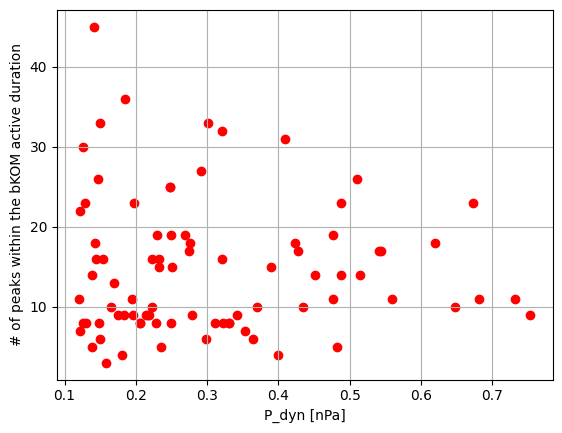

In [5]:
for item in zip(df_final_P["forcing_peak_value"],df_final_P["n_peaks"]):
    if item[1] != 0:
        plt.scatter(item[0],item[1], color= 'red')

plt.xlabel("P_dyn [nPa]")
plt.ylabel("# of peaks within the bKOM active duration")
plt.grid()
plt.show()

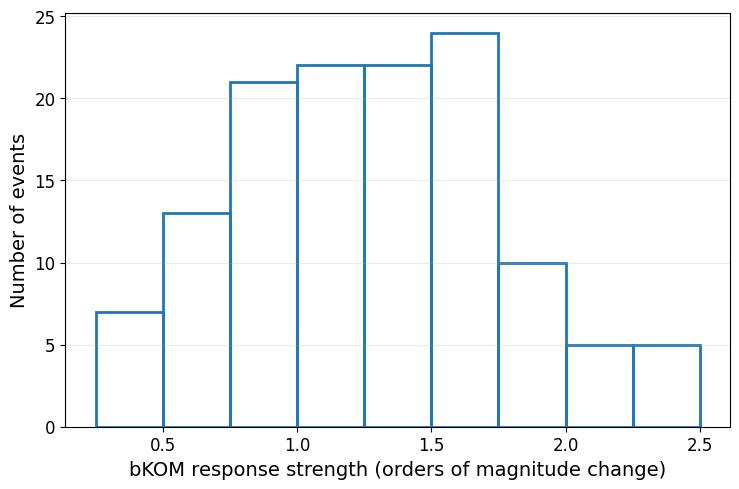

In [7]:
data = df_final_P["jump_log"].dropna()
bins = np.arange(0.25, 2.75, 0.25)

plt.figure(figsize=(7.5, 5))
plt.hist(data, bins=bins, edgecolor='C0', facecolor='none', linewidth=2)

plt.xlabel("bKOM response strength (orders of magnitude change)", fontsize=14)
plt.ylabel("Number of events", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig("plots_rep/jump.pdf", bbox_inches="tight")
plt.show()

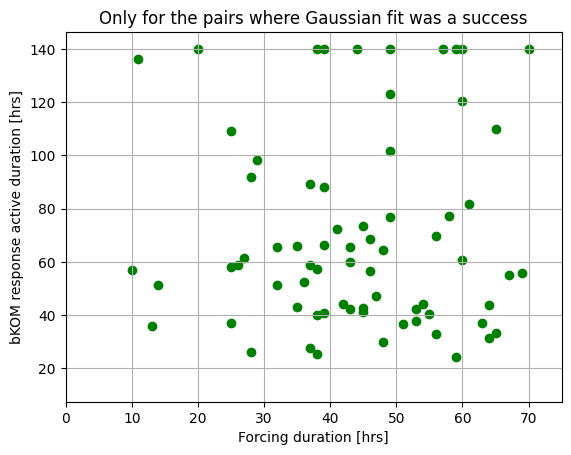

In [5]:
for item in zip (df_final_P["forcing_duration_hr"],df_final_P["active_duration_hr"], df_final_P["fit_success"]):
    if item[2] == True:
        plt.scatter(item[0], item[1], color = 'green')

#plt.scatter(df_final["forcing_peak_value"],df_final["active_duration_hr"])
plt.title("Only for the pairs where Gaussian fit was a success")
plt.xlabel("Forcing duration [hrs]")
plt.ylabel("bKOM response active duration [hrs]")
plt.xlim(0,75)
plt.grid()
plt.show()

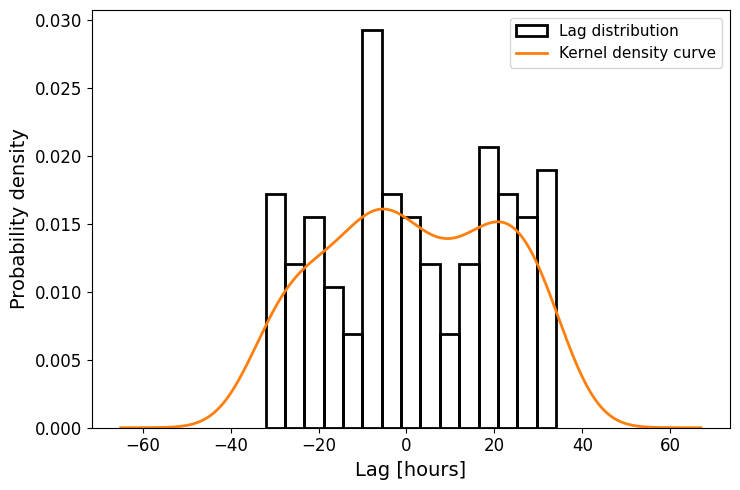

In [14]:
data = df_final_P["lag_hours_onset"].dropna()

fig, ax = plt.subplots(figsize=(7.5, 5))

data.plot.hist(bins=15, density=True, edgecolor='k', facecolor='none',
               ax=ax, label='Lag distribution', linewidth=2)
data.plot.kde(lw=2, ax=ax, label='Kernel density curve')

plt.xlabel("Lag [hours]", fontsize=14)
plt.ylabel("Probability density", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("plots_rep/lags.pdf", bbox_inches="tight")
plt.show()

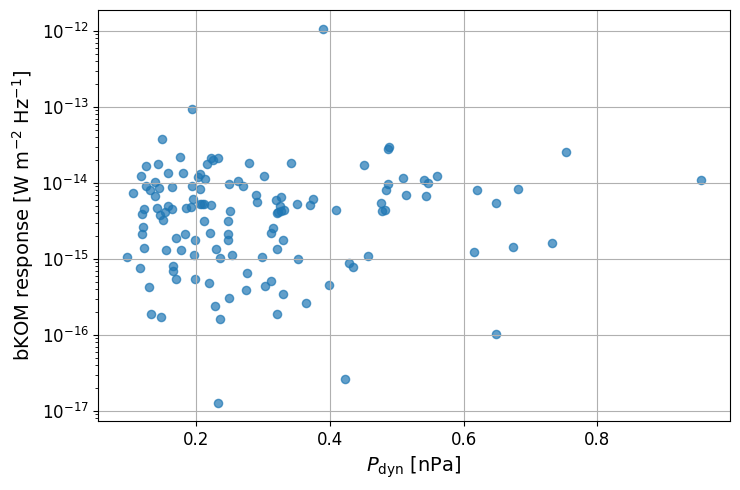

In [16]:
plt.figure(figsize=(7.5, 5))

plt.scatter(df_final_P["forcing_peak_value"], 10**df_final_P["peak_log"], s=35, alpha=0.7)

plt.xlabel(r"$P_{\rm dyn}$ [nPa]", fontsize=14)
plt.ylabel(r"bKOM response [W m$^{-2}$ Hz$^{-1}$]", fontsize=14)
plt.yscale("log")

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()

plt.tight_layout()
plt.savefig("plots_rep/pressureVsbKOM.pdf", bbox_inches="tight")
plt.show()

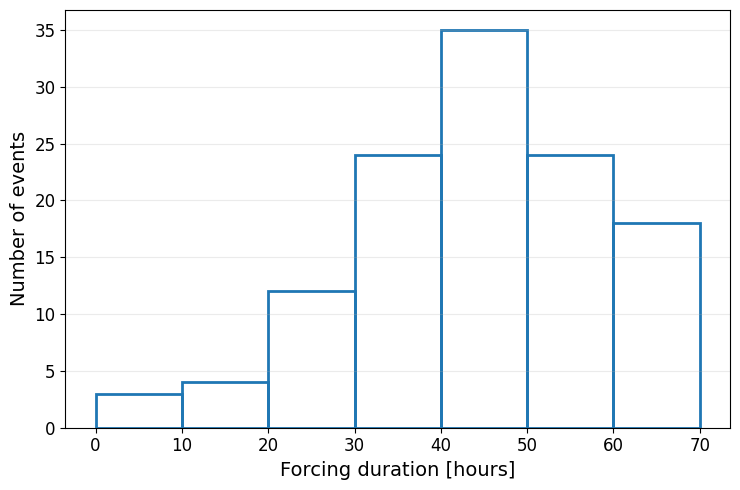

In [17]:
plt.figure(figsize=(7.5, 5))

plt.hist(df_final_P["forcing_duration_hr"].dropna(),
         bins=np.arange(0, 80, 10),
         edgecolor='C0', facecolor='none', linewidth=2)

plt.xlabel("Forcing duration [hours]", fontsize=14)
plt.ylabel("Number of events", fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("plots_rep/forcing.pdf", bbox_inches="tight")
plt.show()

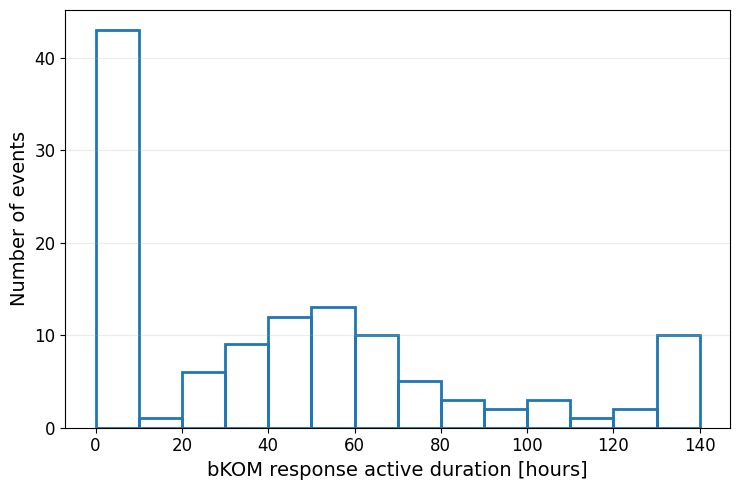

In [18]:
data = df_final_P.loc[df_final_P["active_duration_hr"] > 1, "active_duration_hr"]

plt.figure(figsize=(7.5, 5))

plt.hist(data, bins=np.arange(0, 150, 10),
         edgecolor='C0', facecolor='none', linewidth=2)

plt.xlabel("bKOM response active duration [hours]", fontsize=14)
plt.ylabel("Number of events", fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig("plots_rep/active.pdf", bbox_inches="tight")
plt.show()

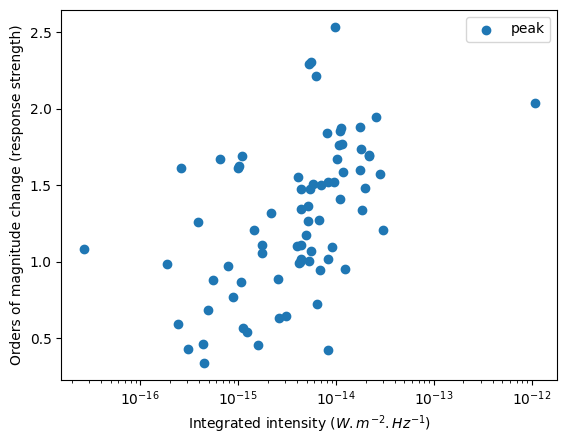

In [ ]:
#plt.scatter(10**df_final["baseline_log"], df_final["jump_log"], label='baseline')
plt.scatter(10**df_final["peak_log"], df_final["jump_log"], label='peak')
plt.ylabel("Orders of magnitude change (response strength)")
plt.xlabel("Integrated intensity ($W.m^{-2}.Hz^{-1}$)")
#plt.xlim(10**-16, 10**-14)
plt.legend()
plt.xscale('log')

count    132.000000
mean       0.294255
std        0.161988
min        0.096800
5%         0.121432
10%        0.133367
25%        0.174067
50%        0.247750
75%        0.355800
90%        0.513517
95%        0.632295
max        0.955367
Name: forcing_peak_value, dtype: float64


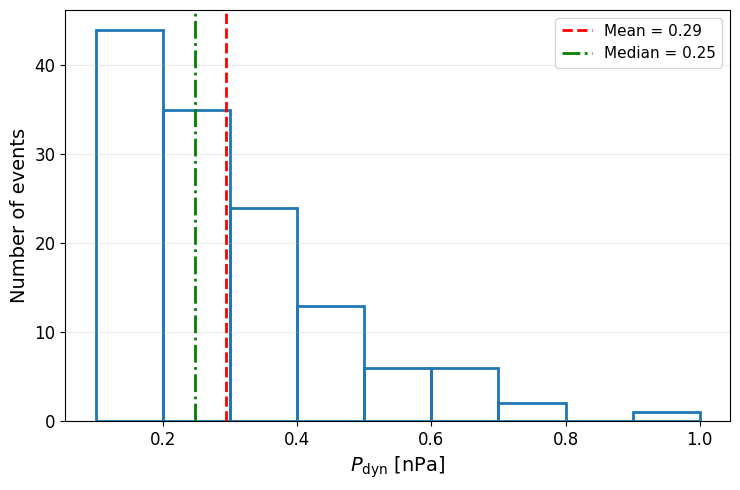

In [19]:
data = df_final_P["forcing_peak_value"].dropna()

print(data.describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

mean = data.mean()
median = data.median()

plt.figure(figsize=(7.5, 5))

plt.hist(data, bins=np.arange(0.1, 1.1, 0.1),
         facecolor='none', edgecolor='C0', linewidth=2)

plt.axvline(mean, color='red', ls='--', lw=2, label=f"Mean = {mean:.2f}")
plt.axvline(median, color='green', ls='-.', lw=2, label=f"Median = {median:.2f}")

plt.xlabel(r"$P_{\rm dyn}$ [nPa]", fontsize=14)
plt.ylabel("Number of events", fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="y", alpha=0.25)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("plots_rep/pressure.pdf", bbox_inches="tight")
plt.show()

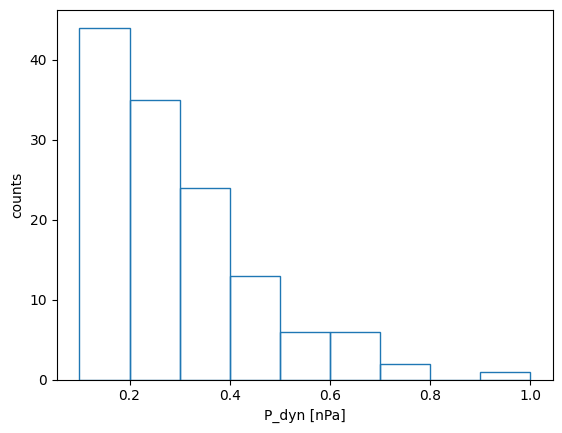

In [27]:
plt.hist((df_final_P["forcing_peak_value"].dropna()), bins=np.array([0.1,0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]), facecolor='none', edgecolor='C0')
plt.ylabel('counts')
plt.xscale("linear")
plt.xlabel('P_dyn [nPa]')
plt.savefig("plots/pressure.pdf")
plt.show()

count    102.000000
mean       1.597774
std        0.666608
min        0.519367
5%         0.766242
10%        0.858856
25%        1.189442
50%        1.443633
75%        1.962467
90%        2.372140
95%        3.066433
max        3.575733
Name: forcing_peak_value, dtype: float64


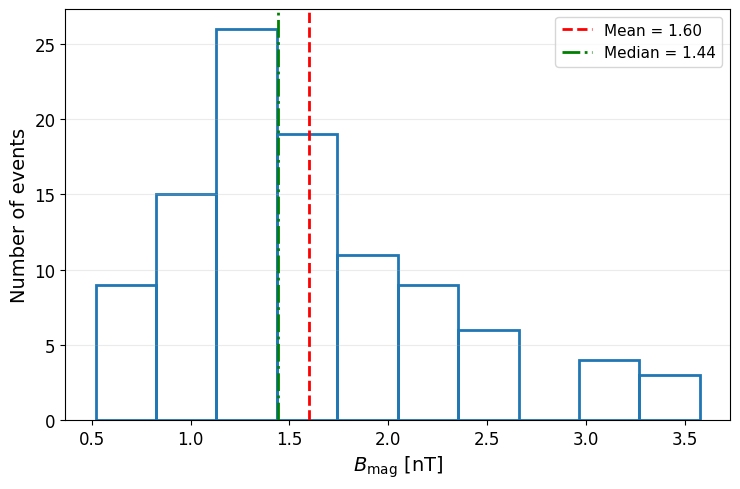

In [20]:
data = df_final_B["forcing_peak_value"].dropna()

print(data.describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

mean = data.mean()
median = data.median()

plt.figure(figsize=(7.5, 5))

plt.hist(data, bins=10, facecolor='none', edgecolor='C0', linewidth=2)

plt.axvline(mean, color='red', ls='--', lw=2, label=f"Mean = {mean:.2f}")
plt.axvline(median, color='green', ls='-.', lw=2, label=f"Median = {median:.2f}")

plt.xlabel(r"$B_{\rm mag}$ [nT]", fontsize=14)
plt.ylabel("Number of events", fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="y", alpha=0.25)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("plots_rep/magnetic_field.pdf", bbox_inches="tight")
plt.show()

count    144.000000
mean       0.878658
std        0.490589
min        0.244467
5%         0.393728
10%        0.441750
25%        0.526350
50%        0.733217
75%        1.038350
90%        1.544423
95%        1.999143
max        2.845700
Name: forcing_peak_value, dtype: float64


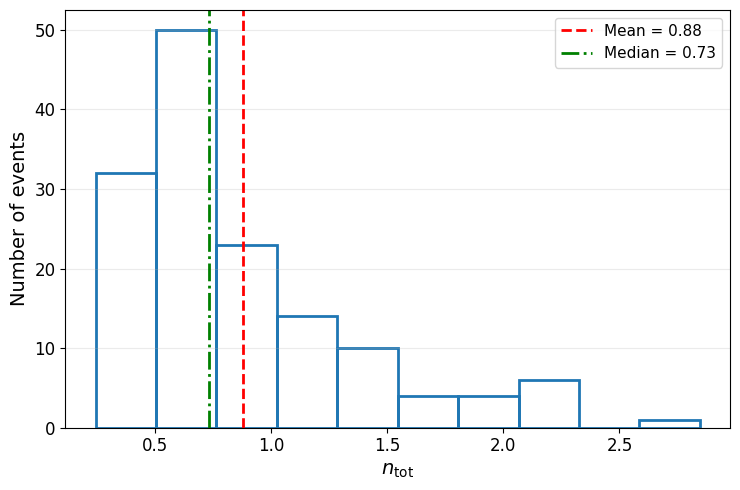

In [22]:
data = df_final_N["forcing_peak_value"].dropna()

print(data.describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

mean = data.mean()
median = data.median()

plt.figure(figsize=(7.5, 5))

plt.hist(data, bins=10, facecolor='none', edgecolor='C0', linewidth=2)

plt.axvline(mean, color='red', ls='--', lw=2, label=f"Mean = {mean:.2f}")
plt.axvline(median, color='green', ls='-.', lw=2, label=f"Median = {median:.2f}")

plt.xlabel(r"$n_{\rm tot}$", fontsize=14)
plt.ylabel("Number of events", fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="y", alpha=0.25)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("plots_rep/density.pdf", bbox_inches="tight")
plt.show()

count    132.000000
mean     -14.478986
std        0.680809
min      -16.888688
5%       -15.663742
10%      -15.356958
25%      -14.888291
50%      -14.343770
75%      -14.041834
90%      -13.752746
95%      -13.662400
max      -11.970635
Name: peak_log, dtype: float64


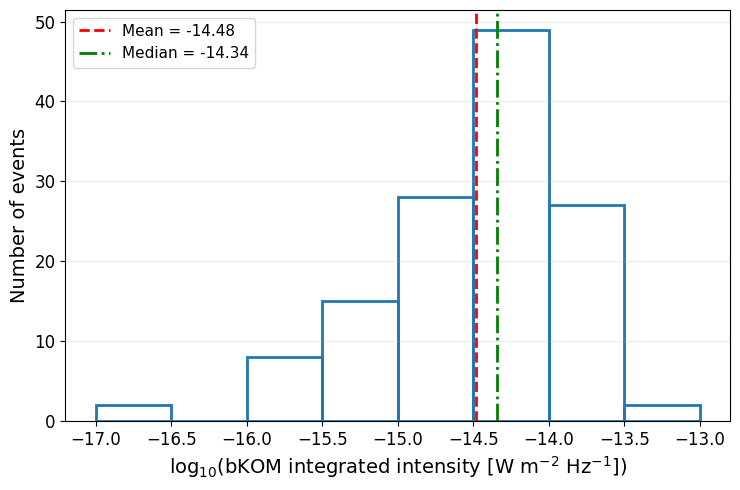

In [23]:
data = df_final_P["peak_log"].dropna()

print(data.describe(percentiles=[0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

mean = data.mean()
median = data.median()

plt.figure(figsize=(7.5, 5))

plt.hist(data, bins=np.arange(-17, -12.5, 0.5),
         facecolor='none', edgecolor='C0', linewidth=2)

plt.axvline(mean, color='red', ls='--', lw=2, label=f"Mean = {mean:.2f}")
plt.axvline(median, color='green', ls='-.', lw=2, label=f"Median = {median:.2f}")

plt.xlabel(r"log$_{10}$(bKOM integrated intensity [W m$^{-2}$ Hz$^{-1}$])", fontsize=14)
plt.ylabel("Number of events", fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis="y", alpha=0.25)
plt.legend(fontsize=11)

plt.tight_layout()
plt.savefig("plots_rep/bKOM.pdf", bbox_inches="tight")
plt.show()

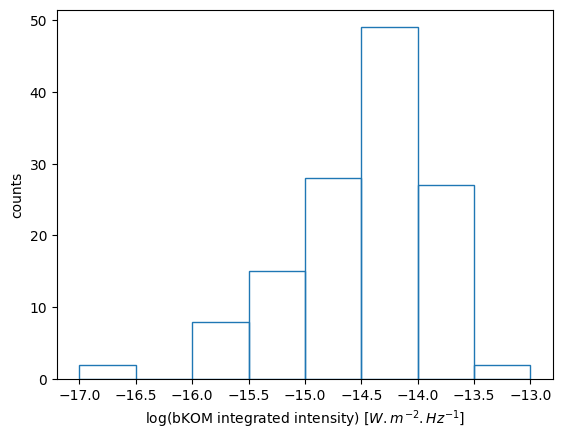

In [30]:
plt.hist(df_final_P["peak_log"], bins = [-17,-16.5,-16,-15.5,-15,-14.5,-14,-13.5, -13], facecolor = 'none', edgecolor='C0' )
plt.xlabel("log(bKOM integrated intensity) $[W.m^{-2}.Hz^{-1}]$")
plt.ylabel("counts") 
plt.savefig("plots/bKOM.pdf")
plt.show()

/tmp/ipykernel_24975/3344291126.py:71: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  hb = ax.scatter(


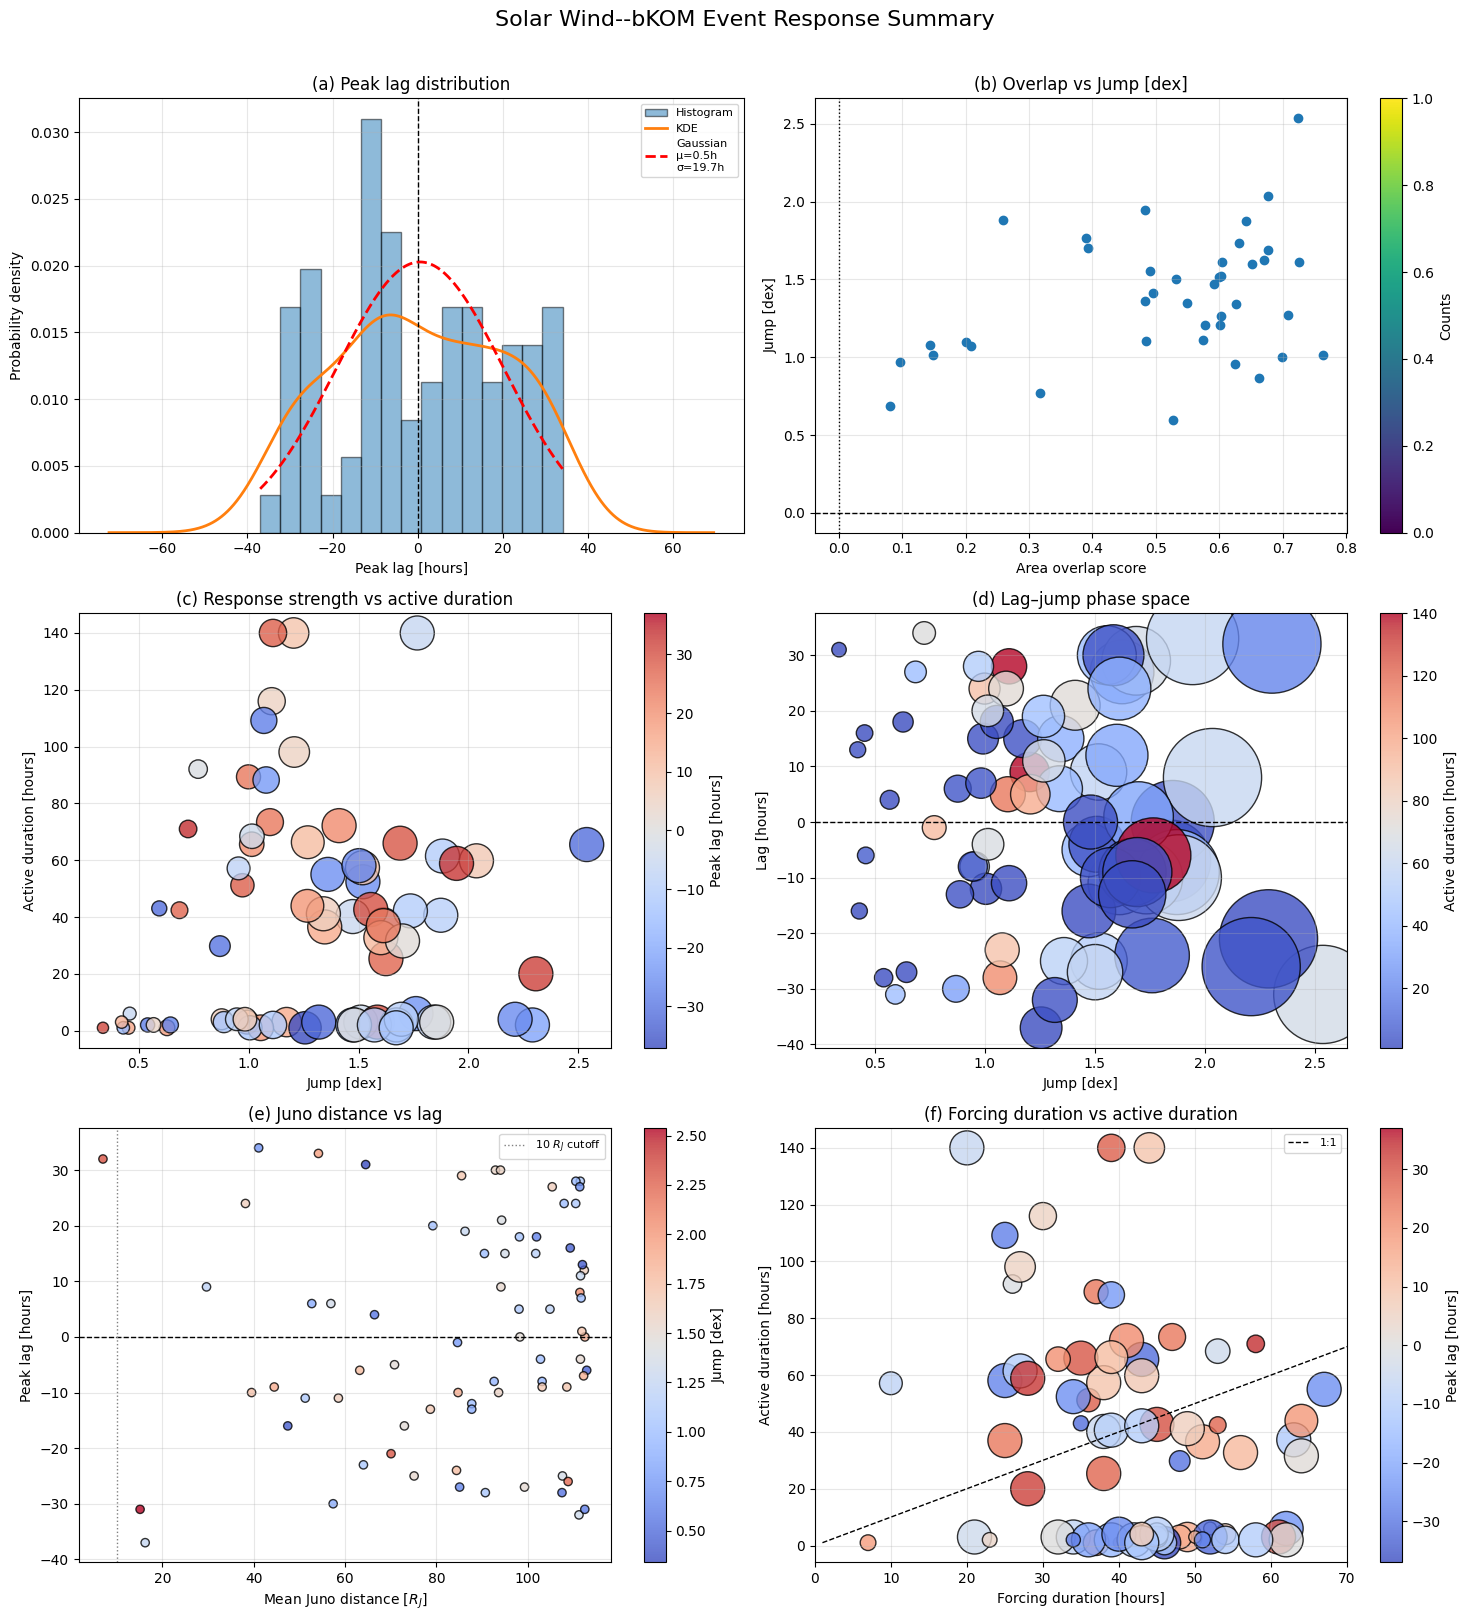

In [26]:
# -----------------------------------------------------------------------------
# Clean dataframe for plotting
# -----------------------------------------------------------------------------
plot_cols = [
    "lag_hours_peak",
    "area_overlap_score",
    "area_overlap_value",
    "jump_log",
    "active_duration_hr",
    "response_ratio",
    "r_mean_RJ",
    "forcing_duration_hr"
]

df_plot = df_final[plot_cols].replace([np.inf, -np.inf], np.nan)

fig, axs = plt.subplots(3, 2, figsize=(15, 16))

# =============================================================================
# 1. Lag distribution
# =============================================================================

ax = axs[0, 0]

df_plot["lag_hours_peak"].dropna().plot.hist(
    bins=15,
    density=True,
    alpha=0.5,
    edgecolor="k",
    ax=ax,
    label="Histogram"
)

df_plot["lag_hours_peak"].dropna().plot.kde(
    lw=2,
    ax=ax,
    label="KDE"
)

mu, sigma = norm.fit(df_plot["lag_hours_peak"].dropna())

x = np.linspace(
    df_plot["lag_hours_peak"].min(),
    df_plot["lag_hours_peak"].max(),
    500
)

ax.plot(
    x,
    norm.pdf(x, mu, sigma),
    color="red",
    linestyle="--",
    lw=2,
    label=f"Gaussian\nμ={mu:.1f}h\nσ={sigma:.1f}h"
)

ax.axvline(0, color="k", linestyle="--", lw=1)
ax.set_xlabel("Peak lag [hours]")
ax.set_ylabel("Probability density")
ax.set_title("(a) Peak lag distribution")
ax.legend(fontsize=8)

# =============================================================================
# 2. Overlap score vs lag
# =============================================================================

ax = axs[0, 1]

valid = df_plot[["area_overlap_score", "jump_log"]].dropna()

hb = ax.scatter(
    valid["area_overlap_score"],
    valid["jump_log"],
    cmap="coolwarm"
)

cbar = fig.colorbar(hb, ax=ax)
cbar.set_label("Counts")

ax.axhline(0, color="k", linestyle="--", lw=1)
ax.axvline(0, color="k", linestyle=":", lw=1)

ax.set_xlabel("Area overlap score")
ax.set_ylabel("Jump [dex]")
ax.set_title("(b) Overlap vs Jump [dex]")

# =============================================================================
# 3. Jump vs active duration, coloured by lag
# =============================================================================

ax = axs[1, 0]

valid = df_plot[
    ["jump_log", "active_duration_hr", "lag_hours_peak", "response_ratio"]
].dropna()

sc = ax.scatter(
    valid["jump_log"],
    valid["active_duration_hr"],
    c=valid["lag_hours_peak"],
    cmap="coolwarm",
    norm=colors.CenteredNorm(vcenter=0),
    s=30 * np.clip(valid["response_ratio"], 1, 20),
    edgecolor="k",
    alpha=0.8
)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Peak lag [hours]")

ax.set_xlabel("Jump [dex]")
ax.set_ylabel("Active duration [hours]")
ax.set_title("(c) Response strength vs active duration")

# =============================================================================
# 4. Jump vs lag, coloured by active duration
# =============================================================================

ax = axs[1, 1]

valid = df_plot[
    ["jump_log", "lag_hours_peak", "active_duration_hr", "response_ratio"]
].dropna()

sc = ax.scatter(
    valid["jump_log"],
    valid["lag_hours_peak"],
    s=50 * np.clip(valid["response_ratio"], 1, 100),
    c=valid["active_duration_hr"],
    cmap="coolwarm",
    edgecolor="k",
    alpha=0.8
)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Active duration [hours]")

ax.axhline(0, color="k", linestyle="--", lw=1)
ax.set_xlabel("Jump [dex]")
ax.set_ylabel("Lag [hours]")
ax.set_title("(d) Lag–jump phase space")

# =============================================================================
# 5. Juno distance vs lag
# =============================================================================

ax = axs[2, 0]

valid = df_plot[
    ["r_mean_RJ", "lag_hours_peak", "jump_log", "response_ratio"]
].dropna()

sc = ax.scatter(
    valid["r_mean_RJ"],
    valid["lag_hours_peak"],
    c=valid["jump_log"],
    #s=30 * np.clip(valid["response_ratio"], 1, 20),
    cmap="coolwarm",
    edgecolor="k",
    alpha=0.8
)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Jump [dex]")

ax.axhline(0, color="k", linestyle="--", lw=1)
ax.axvline(10, color="grey", linestyle=":", lw=1, label=r"10 $R_J$ cutoff")

ax.set_xlabel(r"Mean Juno distance [$R_J$]")
ax.set_ylabel("Peak lag [hours]")
ax.set_title("(e) Juno distance vs lag")
ax.legend(fontsize=8)

# =============================================================================
# 6. Active duration vs forcing duration
# =============================================================================

ax = axs[2, 1]

valid = df_plot[
    ["forcing_duration_hr", "active_duration_hr", "lag_hours_peak", "response_ratio"]
].dropna()

sc = ax.scatter(
    valid["forcing_duration_hr"],
    valid["active_duration_hr"],
    c=valid["lag_hours_peak"],
    cmap="coolwarm",
    norm=colors.CenteredNorm(vcenter=0),
    s=30 * np.clip(valid["response_ratio"], 1, 20),
    edgecolor="k",
    alpha=0.8
)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label("Peak lag [hours]")

lims = [
    min(valid["forcing_duration_hr"].min(), valid["active_duration_hr"].min()),
    max(valid["forcing_duration_hr"].max(), valid["active_duration_hr"].max())
]

ax.plot(lims, lims, "k--", lw=1, label="1:1")

ax.set_xlabel("Forcing duration [hours]")
ax.set_ylabel("Active duration [hours]")
ax.set_xlim(0,70)
ax.set_title("(f) Forcing duration vs active duration")
ax.legend(fontsize=8)

# =============================================================================
# Cosmetics
# =============================================================================

for ax in axs.flat:
    ax.grid(alpha=0.3)

plt.suptitle(
    "Solar Wind--bKOM Event Response Summary",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

In [17]:
# =============================================================================
# Helper: make 3x2 summary dashboard for a lag subset
# =============================================================================

def plot_event_summary_by_lag(df_input, lag_condition="positive"):

    if lag_condition == "positive":
        df_sub = df_input[df_input["lag_hours_peak"] > 0].copy()
        title_suffix = "Positive lags only"
    elif lag_condition == "negative":
        df_sub = df_input[df_input["lag_hours_peak"] < 0].copy()
        title_suffix = "Negative lags only"
    else:
        raise ValueError("lag_condition must be 'positive' or 'negative'")

    plot_cols = [
        "lag_hours_peak",
        "area_overlap_score",
        "area_overlap_value",
        "jump_log",
        "active_duration_hr",
        "response_ratio",
        "r_mean_RJ",
        "forcing_duration_hr"
    ]

    df_plot = df_sub[plot_cols].replace([np.inf, -np.inf], np.nan)

    if len(df_plot.dropna(how="all")) == 0:
        print(f"No valid events for {title_suffix}")
        return

    fig, axs = plt.subplots(3, 2, figsize=(15, 16))

    # =========================================================================
    # 1. Lag distribution
    # =========================================================================

    ax = axs[0, 0]

    lag_data = df_plot["lag_hours_peak"].dropna()

    if len(lag_data) > 0:
        lag_data.plot.hist(
            bins=15,
            density=True,
            alpha=0.5,
            edgecolor="k",
            ax=ax,
            label="Histogram"
        )

        if len(lag_data) > 1:
            lag_data.plot.kde(
                lw=2,
                ax=ax,
                label="KDE"
            )

        if len(lag_data) > 2:
            mu, sigma = norm.fit(lag_data)

            x = np.linspace(
                lag_data.min(),
                lag_data.max(),
                500
            )

            ax.plot(
                x,
                norm.pdf(x, mu, sigma),
                color="red",
                linestyle="--",
                lw=2,
                label=f"Gaussian\nμ={mu:.1f}h\nσ={sigma:.1f}h"
            )

    ax.axvline(0, color="k", linestyle="--", lw=1)
    ax.set_xlabel("Peak lag [hours]")
    ax.set_ylabel("Probability density")
    ax.set_title("(a) Peak lag distribution")
    ax.legend(fontsize=8)

    # =========================================================================
    # 2. Overlap score vs lag
    # =========================================================================

    ax = axs[0, 1]

    valid = df_plot[["area_overlap_score", "lag_hours_peak"]].dropna()

    if len(valid) > 0:
        hb = ax.hexbin(
            valid["area_overlap_score"],
            valid["lag_hours_peak"],
            gridsize=40,
            mincnt=1,
            cmap="coolwarm"
        )

        cbar = fig.colorbar(hb, ax=ax)
        cbar.set_label("Counts")

    ax.axhline(0, color="k", linestyle="--", lw=1)
    ax.axvline(0, color="k", linestyle=":", lw=1)

    ax.set_xlabel("Area overlap score")
    ax.set_ylabel("Peak lag [hours]")
    ax.set_title("(b) Lag vs overlap")

    # =========================================================================
    # 3. Jump vs active duration, coloured by lag
    # =========================================================================

    ax = axs[1, 0]

    valid = df_plot[
        ["jump_log", "active_duration_hr", "lag_hours_peak", "response_ratio"]
    ].dropna()

    if len(valid) > 0:
        sc = ax.scatter(
            valid["jump_log"],
            valid["active_duration_hr"],
            c=valid["lag_hours_peak"],
            cmap="coolwarm",
            norm=colors.CenteredNorm(vcenter=0),
            s=30 * np.clip(valid["response_ratio"], 1, 20),
            edgecolor="k",
            alpha=0.8
        )

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label("Peak lag [hours]")

    ax.set_xlabel("Jump [dex]")
    ax.set_ylabel("Active duration [hours]")
    ax.set_title("(c) Response strength vs active duration")

    # =========================================================================
    # 4. Jump vs lag, coloured by active duration
    # =========================================================================

    ax = axs[1, 1]

    valid = df_plot[
        ["jump_log", "lag_hours_peak", "active_duration_hr", "response_ratio"]
    ].dropna()

    if len(valid) > 0:
        sc = ax.scatter(
            valid["jump_log"],
            valid["lag_hours_peak"],
            s=50 * np.clip(valid["response_ratio"], 1, 100),
            c=valid["active_duration_hr"],
            cmap="coolwarm",
            edgecolor="k",
            alpha=0.8
        )

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label("Active duration [hours]")

    ax.axhline(0, color="k", linestyle="--", lw=1)
    ax.set_xlabel("Jump [dex]")
    ax.set_ylabel("Lag [hours]")
    ax.set_title("(d) Lag–jump phase space")

    # =========================================================================
    # 5. Juno distance vs lag
    # =========================================================================

    ax = axs[2, 0]

    valid = df_plot[
        ["r_mean_RJ", "lag_hours_peak", "jump_log", "response_ratio"]
    ].dropna()

    if len(valid) > 0:
        sc = ax.scatter(
            valid["r_mean_RJ"],
            valid["lag_hours_peak"],
            c=valid["jump_log"],
            s=30 * np.clip(valid["response_ratio"], 1, 20),
            cmap="coolwarm",
            edgecolor="k",
            alpha=0.8
        )

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label("Jump [dex]")

    ax.axhline(0, color="k", linestyle="--", lw=1)
    ax.axvline(10, color="grey", linestyle=":", lw=1, label=r"10 $R_J$ cutoff")

    ax.set_xlabel(r"Mean Juno distance [$R_J$]")
    ax.set_ylabel("Peak lag [hours]")
    ax.set_title("(e) Juno distance vs lag")
    ax.legend(fontsize=8)

    # =========================================================================
    # 6. Active duration vs forcing duration
    # =========================================================================

    ax = axs[2, 1]

    valid = df_plot[
        ["forcing_duration_hr", "active_duration_hr", "lag_hours_peak", "response_ratio"]
    ].dropna()

    if len(valid) > 0:
        sc = ax.scatter(
            valid["forcing_duration_hr"],
            valid["active_duration_hr"],
            c=valid["lag_hours_peak"],
            cmap="coolwarm",
            norm=colors.CenteredNorm(vcenter=0),
            s=30 * np.clip(valid["response_ratio"], 1, 20),
            edgecolor="k",
            alpha=0.8
        )

        cbar = fig.colorbar(sc, ax=ax)
        cbar.set_label("Peak lag [hours]")

        lims = [
            min(valid["forcing_duration_hr"].min(), valid["active_duration_hr"].min()),
            max(valid["forcing_duration_hr"].max(), valid["active_duration_hr"].max())
        ]

        ax.plot(
            lims,
            lims,
            "k--",
            lw=1,
            label="1:1"
        )

    ax.set_xlabel("Forcing duration [hours]")
    ax.set_ylabel("Active duration [hours]")
    ax.set_title("(f) Forcing duration vs active duration")
    ax.set_xlim(0,70)
    ax.legend(fontsize=8)

    # =========================================================================
    # Cosmetics
    # =========================================================================

    for ax in axs.flat:
        ax.grid(alpha=0.3)

    plt.suptitle(
        f"Solar Wind--bKOM Event Response Summary — {title_suffix}",
        fontsize=16,
        y=1.01
    )

    plt.tight_layout()
    plt.show()

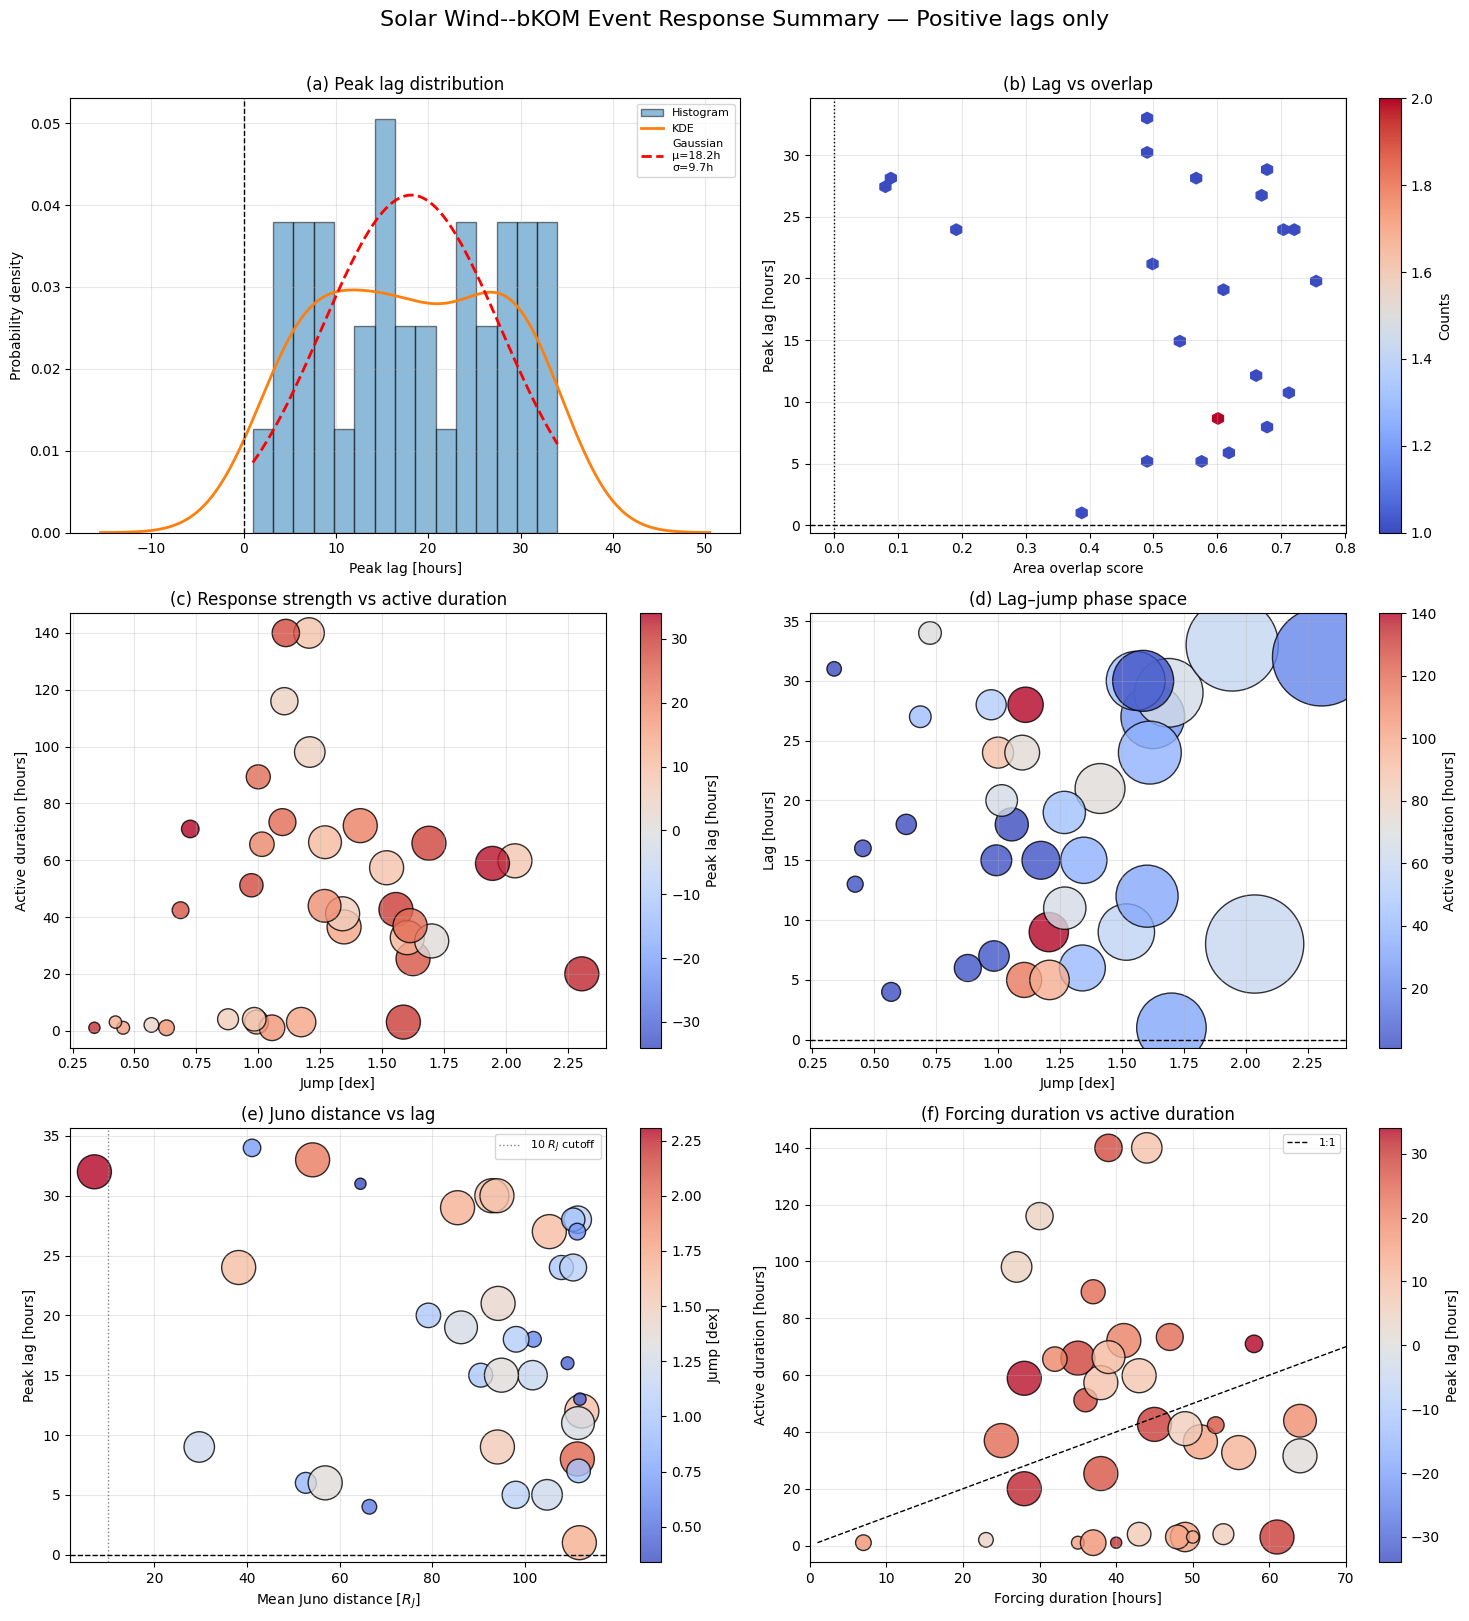

In [18]:
plot_event_summary_by_lag(df_final, lag_condition="positive")

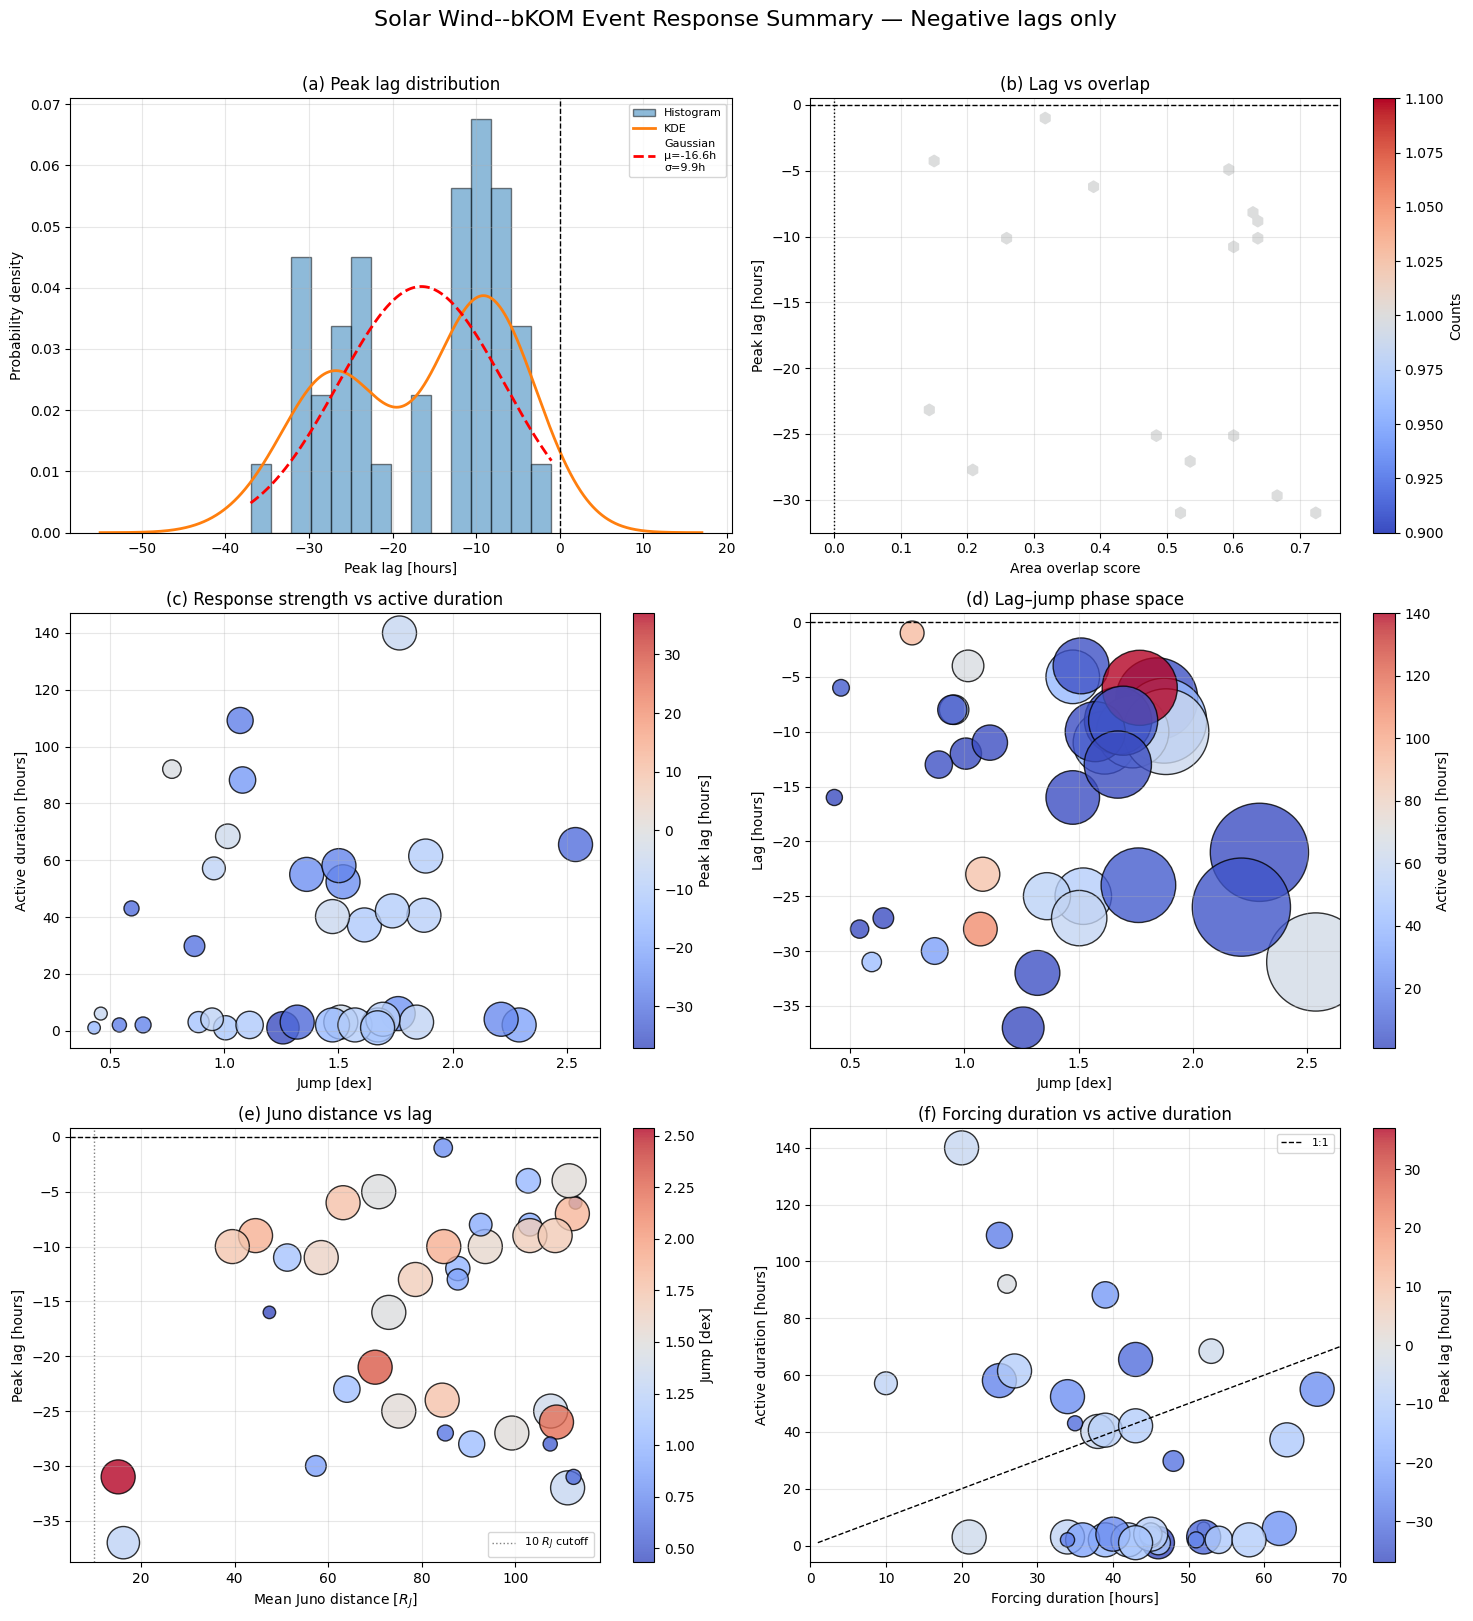

In [19]:
plot_event_summary_by_lag(df_final, lag_condition="negative")